# Финансовые новости — анализ тональности
## День 1 из 7. Загрузка и первичный анализ

Учебная задача: по английскому предложению из финансовой новости определить
**negative**, **neutral** или **positive**. Тональность рассматривается с точки зрения инвестора.

**Весь проект ведём в этом ноутбуке. Выполнены все семь дней. README и итоговая сводка — в Дне 7.**
В следующие дни дополняем файл по порядку:

| День | Этап |
|---|---|
| 1 | Данные, качество и EDA — выполнено |
| 2 | Очистка, нормализация, признаки и метки — выполнено |
| 3 | Разбиение данных и baseline TF-IDF + Logistic Regression — выполнено |
| 4 | Минимум три улучшения и сравнение macro F1 — выполнено |
| 5 | Матрица ошибок и разбор неверных предсказаний — выполнено |
| 6 | Сохранение модели и предсказания новых текстов — выполнено |
| 7 | Инструкция запуска, демонстрация и финальная проверка — выполнено |

### Как запустить
Выберите Python-ядро Jupyter и выполните **Run All / Выполнить всё** сверху вниз.
Нужны `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `joblib`, `ipykernel` и `IPython`.
Если их нет, выполните в отдельной ячейке:
`%pip install pandas matplotlib seaborn scikit-learn joblib ipykernel` и перезапустите ядро.

Для загрузки датасета нужен интернет. Архив читается прямо в память: отдельный CSV
и файлы предыдущего проекта не нужны. Все таблицы и графики показаны прямо здесь.

### 1. Источник и выбор датасета

Используем **Financial PhraseBank**, вариант `Sentences_50Agree.txt`:
для включённых предложений согласие аннотаторов составляет не менее 50%.
Это даёт больше примеров, но допускает неоднозначные метки.
Варианты 66%, 75% и 100% — альтернативные подвыборки; объединять их нельзя,
поскольку предложения пересекаются.

- [Карточка датасета](https://huggingface.co/datasets/takala/financial_phrasebank).
- [Скачать датасет](https://huggingface.co/datasets/takala/financial_phrasebank/resolve/8d3fe0c36d5feec6b3cc5e455b0fcb4820fb9964/data/FinancialPhraseBank-v1.0.zip).
- Авторы: Pekka Malo, Ankur Sinha, Pekka Korhonen, Jyrki Wallenius, Pyry Takala.
  [Статья о датасете](https://arxiv.org/abs/1307.5336).
- Лицензия данных: [CC BY-NC-SA 3.0](https://creativecommons.org/licenses/by-nc-sa/3.0/).
  Использование данных регулируется этой лицензией.

Архив прочитан как ZIP, текст декодирован в `latin-1`, строки разделены по последнему `@`.
После чтения исходных строк создаётся CSV в памяти с колонками `text,sentiment`.
**Фактический размер выбранного файла — 4 846 строк**; число 4 840 в кратком описании
карточки отличается. В расчётах используем содержимое закреплённого файла.

In [1]:
import hashlib
import io
import platform
import zipfile
from urllib.request import urlopen

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110})
CLASS_ORDER = ["negative", "neutral", "positive"]
PALETTE = {"negative": "#D65F5F", "neutral": "#7A8EA3", "positive": "#49A078"}
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "matplotlib:", matplotlib.__version__, "seaborn:", sns.__version__)

Python: 3.13.5
pandas: 2.2.3 matplotlib: 3.10.0 seaborn: 0.13.2


### 2. Загрузка данных

Скачиваем архив по закреплённой версии, проверяем его контрольную сумму и читаем
предложения в память. Интернет нужен при каждом запуске этой ячейки.
Данные не хранятся длинной строкой внутри кода и не записываются отдельным файлом.

In [2]:
SOURCE_REVISION = "8d3fe0c36d5feec6b3cc5e455b0fcb4820fb9964"
BASE_URL = "https://huggingface.co/datasets/takala/financial_phrasebank"
url = f"{BASE_URL}/resolve/{SOURCE_REVISION}/data/FinancialPhraseBank-v1.0.zip"
expected_sha256 = "0e1a06c4900fdae46091d031068601e3773ba067c7cecb5b0da1dcba5ce989a6"

with urlopen(url, timeout=60) as response:
    archive_bytes = response.read()
assert hashlib.sha256(archive_bytes).hexdigest() == expected_sha256, "Архив повреждён"

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    text = archive.read("FinancialPhraseBank-v1.0/Sentences_50Agree.txt").decode("latin-1")
rows = [line.rsplit("@", 1) for line in text.splitlines() if line.strip()]
csv_text = pd.DataFrame(rows, columns=["text", "sentiment"]).to_csv(index=False)
df_raw = pd.read_csv(io.StringIO(csv_text))

assert list(df_raw.columns) == ["text", "sentiment"]
assert len(df_raw) == 4846
print("Размерность:", df_raw.shape)
display(df_raw.head())

Размерность: (4846, 2)


,text,sentiment
0,"According to Gran , the company has no plans t...",neutral
1,Technopolis plans to develop in stages an area...,neutral
2,The international electronic industry company ...,negative
3,With the new production plant the company woul...,positive
4,According to the company 's updated strategy f...,positive


In [3]:
print("Типы данных и заполненность:")
df_raw.info()
print("\nПропуски по колонкам:")
display(df_raw.isna().sum().rename("missing").to_frame())

missing_text = df_raw["text"].isna()
blank_text = df_raw["text"].fillna("").str.strip().eq("")
bad_label = ~df_raw["sentiment"].isin(CLASS_ORDER)
quality_report = pd.Series({
    "Всего строк": len(df_raw),
    "Пропуски текста": int(missing_text.sum()),
    "Пустые/пробельные тексты без пропусков": int((blank_text & ~missing_text).sum()),
    "Пропуски метки": int(df_raw["sentiment"].isna().sum()),
    "Неизвестные или пропущенные метки": int(bad_label.sum()),
    "Повторные пары текст + метка": int(df_raw.duplicated(["text", "sentiment"]).sum()),
    "Повторные тексты": int(df_raw.duplicated("text").sum()),
}, name="Количество")
display(quality_report.to_frame())

# Для EDA убираем только строки, непригодные для анализа. Исходник сохраняем.
valid_rows = ~missing_text & ~blank_text & ~bad_label
df = df_raw.loc[valid_rows].copy()
assert len(df) > 0 and set(df["sentiment"]) == set(CLASS_ORDER)
print("Строк для EDA:", len(df), "| исключено:", int((~valid_rows).sum()))

# Диагностика противоречивой разметки. Дубликаты пока не удаляем.
labels_per_text = df.groupby("text")["sentiment"].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1].index
print("Текстов с несколькими разными метками:", len(conflicting_texts))
if len(conflicting_texts):
    display(df[df["text"].isin(conflicting_texts)].sort_values("text").head(10))

Типы данных и заполненность:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4846 entries, 0 to 4845
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   text       4846 non-null   object
 1   sentiment  4846 non-null   object
dtypes: object(2)
memory usage: 75.8+ KB

Пропуски по колонкам:


,missing
text,0
sentiment,0


,Количество
Всего строк,4846
Пропуски текста,0
Пустые/пробельные тексты без пропусков,0
Пропуски метки,0
Неизвестные или пропущенные метки,0
Повторные пары текст + метка,6
Повторные тексты,8


Строк для EDA: 4846 | исключено: 0
Текстов с несколькими разными метками: 2


,text,sentiment
78,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sel...,neutral
79,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sel...,positive
788,The Group 's business is balanced by its broad...,positive
789,The Group 's business is balanced by its broad...,neutral


### 3. Распределение классов

Количество и доля примеров показывают дисбаланс. Для будущих моделей основная
метрика — **macro F1**: каждый из трёх классов получает одинаковый вес.
Accuracy будем рассматривать дополнительно.

,Количество,"Доля, %"
sentiment,,
negative,604,12.46
neutral,2879,59.41
positive,1363,28.13


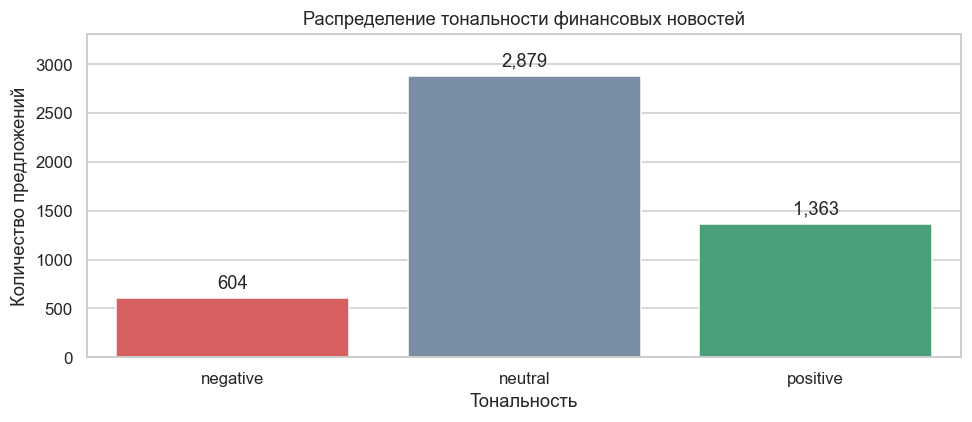

In [4]:
class_counts = df["sentiment"].value_counts().reindex(CLASS_ORDER, fill_value=0)
class_table = class_counts.rename("Количество").to_frame()
class_table["Доля, %"] = (100 * class_counts / len(df)).round(2)
display(class_table)

fig, ax = plt.subplots()
sns.countplot(data=df, x="sentiment", order=CLASS_ORDER, color="#648BA8", ax=ax)
for bar, label in zip(ax.patches, CLASS_ORDER):
    bar.set_facecolor(PALETTE[label])
    ax.annotate(f"{int(bar.get_height()):,}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
ax.set(title="Распределение тональности финансовых новостей", xlabel="Тональность", ylabel="Количество предложений")
ax.margins(y=0.15)
fig.tight_layout()
plt.show()
plt.close(fig)

### 4. Длины текстов

`text_length` — число символов с пробелами, `word_count` — число фрагментов,
разделённых пробельными символами. Это простая оценка длины, а не лингвистическая
токенизация. Исходная пунктуация сохранена.

,text_length,word_count
count,4846.0,4846.0
mean,128.1,23.1
std,56.5,10.0
min,9.0,2.0
50%,119.0,21.0
90%,210.0,38.0
95%,233.8,42.0
99%,275.6,50.0
max,315.0,81.0


text_length                        word_count                     
                count   mean median min  max      count  mean median min max
sentiment                                                                   
negative          604  125.8  118.0  37  296        604  23.9   22.0   5  56
neutral          2879  125.1  116.0   9  315       2879  22.2   21.0   2  81
positive         1363  135.6  128.0  24  298       1363  24.7   23.0   5  57

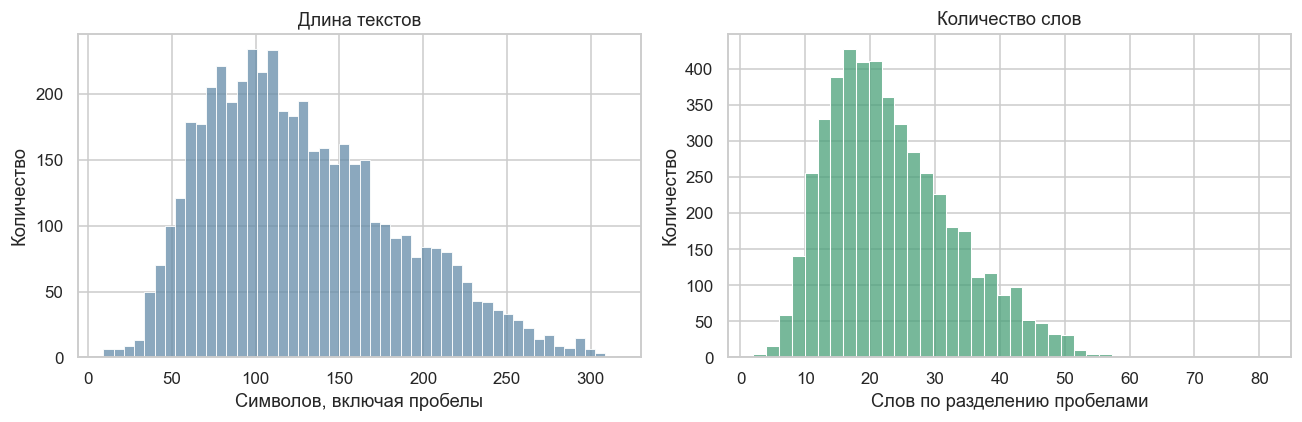

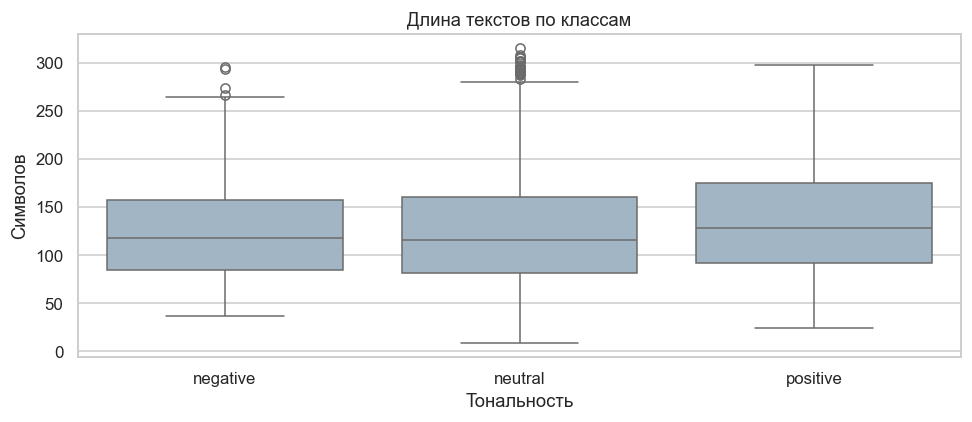

In [5]:
df["text_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()
display(df[["text_length", "word_count"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))
display(df.groupby("sentiment")[["text_length", "word_count"]]
        .agg(["count", "mean", "median", "min", "max"]).reindex(CLASS_ORDER).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="text_length", bins=50, color="#648BA8", ax=axes[0])
axes[0].set(title="Длина текстов", xlabel="Символов, включая пробелы", ylabel="Количество")
sns.histplot(data=df, x="word_count", bins=40, color="#49A078", ax=axes[1])
axes[1].set(title="Количество слов", xlabel="Слов по разделению пробелами", ylabel="Количество")
fig.tight_layout()
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df, x="sentiment", y="text_length", order=CLASS_ORDER, color="#9BB6CA", ax=ax)
ax.set(title="Длина текстов по классам", xlabel="Тональность", ylabel="Символов")
fig.tight_layout()
plt.show()
plt.close(fig)

### 5. Примеры и крайние длины

Покажем по три исходных предложения каждого класса. Короткие и длинные тексты
проверяем отдельно: крайняя длина сама по себе не означает ошибку данных.

In [6]:
with pd.option_context("display.max_colwidth", None):
    for sentiment in CLASS_ORDER:
        print(f"\n=== {sentiment} ===")
        display(df.loc[df["sentiment"].eq(sentiment), ["text", "sentiment", "word_count"]].head(3))
    print("\nТри самых коротких текста:")
    display(df.nsmallest(3, "text_length")[["text", "sentiment", "text_length"]])
    print("\nТри самых длинных текста:")
    display(df.nlargest(3, "text_length")[["text", "sentiment", "text_length"]])


=== negative ===


,text,sentiment,word_count
2,"The international electronic industry company Elcoteq has laid off tens of employees from its Tallinn facility ; contrary to earlier layoffs the company contracted the ranks of its office workers , the daily Postimees reported .",negative,36
415,A tinyurl link takes users to a scamming site promising that users can earn thousands of dollars by becoming a Google ( NASDAQ : GOOG ) Cash advertiser .,negative,29
421,"Compared with the FTSE 100 index , which rose 36.7 points ( or 0.6 % ) on the day , this was a relative price change of -0.2 % .",negative,30



=== neutral ===


,text,sentiment,word_count
0,"According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .",neutral,25
1,"Technopolis plans to develop in stages an area of no less than 100,000 square meters in order to host companies working in computer technologies and telecommunications , the statement said .",neutral,31
58,"At the request of Finnish media company Alma Media 's newspapers , research manager Jari Kaivo-oja at the Finland Futures Research Centre at the Turku School of Economics has drawn up a future scenario for Finland 's national economy by using a model developed by the University of Denver .",neutral,50



=== positive ===


,text,sentiment,word_count
3,With the new production plant the company would increase its capacity to meet the expected increase in demand and would improve the use of raw materials and therefore increase the production profitability .,positive,33
4,"According to the company 's updated strategy for the years 2009-2012 , Basware targets a long-term net sales growth in the range of 20 % -40 % with an operating profit margin of 10 % -20 % of net sales .",positive,41
5,FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is aggressively pursuing its growth strategy by increasingly focusing on technologically more demanding HDI printed circuit boards PCBs .,positive,25



Три самых коротких текста:


,text,sentiment,text_length
1116,Welcome !,neutral,9
2983,It 's not .,neutral,11
3099,R&D Loan ) .,neutral,12



Три самых длинных текста:


,text,sentiment,text_length
1863,"Supported Nokia phones include : N96 , N95-8GB , N95 , N93-N931 , N92 , N85 , N82 , N81 , N80 , N79 , N78 , N77 , N76 , N75 , N73 , N72 , N71 , E90 , E71 , E70 , E66 , E65 , E62 , E61-E61i , E60 , E51 , E50 , Touch Xpress 5800 , 6220 Classic , 6210 Navigator , 6120 Classic , 6110 Navigator , 5700 , 5500 , 5320XM .",neutral,315
62,"`` The new agreement is a continuation to theagreement signed earlier this year with the Lemminkainen Group , whereby Cramo acquired the entire construction machine fleet ofLemminkainen Talo Oy Ita - ja Pohjois Suomo , and signed asimilar agreement , '' said Tatu Hauhio , managing director ofCramo Finland .",neutral,308
2537,"Our customers come from the following countries : UK , USA , Spain , France , Italy , Germany , China , Sweden , Norway , Netherlands , Austria , Belgium , Switzerland , Czech Republic , Serbia , Finland , Canada , Russia , Ukraine , Portugal , Denmark , Ireland , South Korea , Estonia and Liechtenstein .",neutral,306


### 6. Первые выводы

Числа ниже рассчитываются из данных при запуске, чтобы выводы соответствовали таблицам.

In [7]:
majority_class = class_counts.idxmax()
imbalance = class_counts.max() / class_counts.min()
summary = f"""
**Результат Дня 1**

- Загружено **{len(df_raw):,}** предложений; для EDA осталось **{len(df):,}**.
- Классы: negative — **{class_counts['negative']}**, neutral — **{class_counts['neutral']}**,
  positive — **{class_counts['positive']}**.
- Наиболее частый класс — **{majority_class}** ({class_counts.max() / len(df):.1%}).
  Отношение самого большого класса к самому маленькому — **{imbalance:.2f}**.
  Этот дисбаланс нужно учитывать при разбиении и оценке модели.
- Пропусков текста — **{int(missing_text.sum())}**;
  неизвестных/пропущенных меток — **{int(bad_label.sum())}**.
- Повторных строк «текст + метка» — **{int(df_raw.duplicated(['text', 'sentiment']).sum())}**;
  текстов с противоречивыми метками — **{len(conflicting_texts)}**.
  На этапе подготовки потребуется принять явное решение по ним.
- Медианная длина — **{df['text_length'].median():.0f}** символов
  и **{df['word_count'].median():.0f}** слов; 95-й перцентиль —
  **{df['text_length'].quantile(.95):.0f}** символов.

**Что учесть дальше:** согласие аннотаторов от 50% допускает спорные примеры.
Это английские предложения из финансовых новостей, а не поток актуальных котировок.
На этапе моделирования одинаковые очищенные тексты должны попадать в одну часть данных,
а TF-IDF нужно обучать только на train. Для подбора гиперпараметров используем кросс-валидацию внутри train.

**Следующий шаг — День 2:** переиспользуемая очистка, проверка пустых строк после неё,
обработка дубликатов и конфликтов, числовые метки и простые признаки длины.
Обучение моделей сегодня не выполнялось.
"""
display(Markdown(summary))


**Результат Дня 1**

- Загружено **4,846** предложений; для EDA осталось **4,846**.
- Классы: negative — **604**, neutral — **2879**,
  positive — **1363**.
- Наиболее частый класс — **neutral** (59.4%).
  Отношение самого большого класса к самому маленькому — **4.77**.
  Этот дисбаланс нужно учитывать при разбиении и оценке модели.
- Пропусков текста — **0**;
  неизвестных/пропущенных меток — **0**.
- Повторных строк «текст + метка» — **6**;
  текстов с противоречивыми метками — **2**.
  На этапе подготовки потребуется принять явное решение по ним.
- Медианная длина — **119** символов
  и **21** слов; 95-й перцентиль —
  **234** символов.

**Что учесть дальше:** согласие аннотаторов от 50% допускает спорные примеры.
Это английские предложения из финансовых новостей, а не поток актуальных котировок.
На этапе моделирования одинаковые очищенные тексты должны попадать в одну часть данных,
а TF-IDF нужно обучать только на train. Для подбора гиперпараметров используем кросс-валидацию внутри train.

**Следующий шаг — День 2:** переиспользуемая очистка, проверка пустых строк после неё,
обработка дубликатов и конфликтов, числовые метки и простые признаки длины.
Обучение моделей сегодня не выполнялось.


## День 2 из 7. Очистка текста и подготовка признаков

Цель — получить воспроизводимую таблицу для обучения. Используем `df_raw` из Дня 1,
а результат сохраняем в переменной `df_prepared`. Исходные тексты и результаты EDA сохраняются.
Дополнительные файлы не создаём.

### 1. Переиспользуемая очистка текста

Функция `clean_text` нормализует Unicode, раскрывает HTML-сущности, удаляет HTML-теги,
переводит текст в нижний регистр, объединяет пробелы и убирает невидимые символы.
Пропуски и значения, которые не являются строками, превращает в пустую строку.

Сохраняем числа, проценты, валюты, пунктуацию и отрицания: они могут определять смысл
финансовой новости. Лемматизацию и удаление стоп-слов сегодня не применяем.

In [8]:
import html
import re
import unicodedata


def clean_text(text):
    """Очистка одного текста для обучения и будущих предсказаний."""
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKC", html.unescape(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[\u200b\u200c\u200d\ufeff]", "", text)
    return re.sub(r"\s+", " ", text).strip().lower()


manual_examples = [
    (" <b>Profit</b>  rose\n by 5% &amp; revenue hit $100. ",
     "profit rose by 5% & revenue hit $100."),
    ("Company did NOT report a loss.", "company did not report a loss."),
    ("Ｆｕｎｄ\u00a0rose\u200b 2%", "fund rose 2%"),
    ("<p> </p>", ""),
    (None, ""),
    (float("nan"), ""),
    (123, ""),
]
manual_check = pd.DataFrame(manual_examples, columns=["Исходный текст", "Ожидаемый результат"])
manual_check["После очистки"] = manual_check["Исходный текст"].apply(clean_text)
assert manual_check["После очистки"].tolist() == manual_check["Ожидаемый результат"].tolist()
display(manual_check)
print("Проверены HTML, Unicode, пробелы, пропуски, числа, валюта и отрицание.")

,Исходный текст,Ожидаемый результат,После очистки
0,<b>Profit</b> rose\n by 5% &amp; revenue hit...,profit rose by 5% & revenue hit $100.,profit rose by 5% & revenue hit $100.
1,Company did NOT report a loss.,company did not report a loss.,company did not report a loss.
2,Ｆｕｎｄ rose​ 2%,fund rose 2%,fund rose 2%
3,<p> </p>,,
4,None,,
5,NaN,,
6,123,,


Проверены HTML, Unicode, пробелы, пропуски, числа, валюта и отрицание.


### 2. Правила подготовки данных

1. Очистить тексты, удалить пустые результаты и строки с неизвестной меткой.
2. Найти одинаковые **очищенные** тексты с разными метками и исключить все строки этих
   групп: у нас нет основания выбрать одну метку или назначить большинство правильным.
3. Из оставшихся одинаковых очищенных текстов оставить первый пример.
4. Добавить метки `negative → 0`, `neutral → 1`, `positive → 2` и признаки.

Конфликты проверяем до удаления дубликатов. Исходный индекс сохраняем как `source_row`,
чтобы позже сопоставлять ошибки с оригиналом. Повторный запуск использует исходный `df_raw`.

In [9]:
LABEL_TO_ID = {"negative": 0, "neutral": 1, "positive": 2}
ID_TO_LABEL = {value: key for key, value in LABEL_TO_ID.items()}


def prepare_data(frame):
    """Возвращает очищенную таблицу, отчёт об удалениях и конфликтные строки."""
    required = {"text", "sentiment"}
    if not required.issubset(frame.columns):
        raise ValueError("Нужны колонки text и sentiment")

    data = frame[["text", "sentiment"]].copy()
    data.insert(0, "source_row", frame.index.to_numpy())
    report = {"Исходных строк": len(data)}
    data["text_clean"] = data["text"].apply(clean_text)

    empty = data["text_clean"].eq("")
    report["Удалено пустых/некорректных текстов"] = int(empty.sum())
    data = data.loc[~empty].copy()

    unknown = ~data["sentiment"].isin(LABEL_TO_ID)
    report["Удалено строк с неизвестной меткой"] = int(unknown.sum())
    data = data.loc[~unknown].copy()

    label_counts = data.groupby("text_clean")["sentiment"].transform("nunique")
    conflict_mask = label_counts.gt(1)
    conflicts = data.loc[conflict_mask].sort_values(["text_clean", "sentiment"]).copy()
    report["Удалено строк с конфликтующей разметкой"] = int(conflict_mask.sum())
    data = data.loc[~conflict_mask].copy()

    duplicates = data.duplicated("text_clean", keep="first")
    report["Удалено повторных очищенных текстов"] = int(duplicates.sum())
    data = data.loc[~duplicates].copy()

    data["label"] = data["sentiment"].map(LABEL_TO_ID).astype("int64")
    data["word_count_clean"] = data["text_clean"].str.split().str.len()
    data["char_count"] = data["text_clean"].str.len()
    # Символ $ в regex означает конец строки, поэтому его обязательно экранируем.
    data["dollar_count"] = data["text_clean"].str.count(r"\$")
    data = data.reset_index(drop=True)
    report["Осталось строк"] = len(data)
    return data, pd.Series(report, name="Количество"), conflicts


df_prepared, preparation_report, conflicting_rows = prepare_data(df_raw)
display(preparation_report.to_frame())
print("Конфликтных очищенных текстов:", conflicting_rows["text_clean"].nunique())
if not conflicting_rows.empty:
    with pd.option_context("display.max_colwidth", None):
        display(conflicting_rows[["source_row", "text", "sentiment", "text_clean"]])

,Количество
Исходных строк,4846
Удалено пустых/некорректных текстов,0
Удалено строк с неизвестной меткой,0
Удалено строк с конфликтующей разметкой,4
Удалено повторных очищенных текстов,6
Осталось строк,4836


Конфликтных очищенных текстов: 2


,source_row,text,sentiment,text_clean
78,78,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sells stake in Morning Digital Design Oy Finnish IT company TJ Group Plc said on Friday 7 April that it had signed an agreement on selling its shares of Morning Digital Design Oy to Edita Oyj .,neutral,telecomworldwire-7 april 2006-tj group plc sells stake in morning digital design oy finnish it company tj group plc said on friday 7 april that it had signed an agreement on selling its shares of morning digital design oy to edita oyj .
79,79,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sells stake in Morning Digital Design Oy Finnish IT company TJ Group Plc said on Friday 7 April that it had signed an agreement on selling its shares of Morning Digital Design Oy to Edita Oyj .,positive,telecomworldwire-7 april 2006-tj group plc sells stake in morning digital design oy finnish it company tj group plc said on friday 7 april that it had signed an agreement on selling its shares of morning digital design oy to edita oyj .
789,789,The Group 's business is balanced by its broad portfolio of sports and presence in all major markets .,neutral,the group 's business is balanced by its broad portfolio of sports and presence in all major markets .
788,788,The Group 's business is balanced by its broad portfolio of sports and presence in all major markets .,positive,the group 's business is balanced by its broad portfolio of sports and presence in all major markets .


### 3. Проверка полученных текстов и признаков

`word_count_clean` — число слов по пробелам, `char_count` — число символов,
`dollar_count` — число буквальных знаков `$`. Это кандидаты в признаки для следующих дней;
TF-IDF сегодня ещё не обучаем.

In [10]:
with pd.option_context("display.max_colwidth", 120):
    display(df_prepared[["source_row", "text", "text_clean", "sentiment", "label",
                         "word_count_clean", "char_count", "dollar_count"]].head(8))

changed_texts = df_prepared.loc[
    df_prepared["text"].ne(df_prepared["text_clean"]), ["text", "text_clean"]
]
print("Примеры до и после очистки:")
with pd.option_context("display.max_colwidth", None):
    display(changed_texts.head(3))

counts_before = df_raw["sentiment"].value_counts().reindex(CLASS_ORDER, fill_value=0)
counts_after = df_prepared["sentiment"].value_counts().reindex(CLASS_ORDER, fill_value=0)
preparation_comparison = pd.DataFrame({"До подготовки": counts_before, "После подготовки": counts_after})
preparation_comparison["Удалено"] = counts_before - counts_after
preparation_comparison["Доля после, %"] = (100 * counts_after / len(df_prepared)).round(2)
display(preparation_comparison)
display(df_prepared[["word_count_clean", "char_count", "dollar_count"]].describe().round(2))

,source_row,text,text_clean,sentiment,label,word_count_clean,char_count,dollar_count
0,0,"According to Gran , the company has no plans to move all production to Russia , although that is where the company i...","according to gran , the company has no plans to move all production to russia , although that is where the company i...",neutral,1,25,127,0
1,1,"Technopolis plans to develop in stages an area of no less than 100,000 square meters in order to host companies work...","technopolis plans to develop in stages an area of no less than 100,000 square meters in order to host companies work...",neutral,1,31,190,0
2,2,The international electronic industry company Elcoteq has laid off tens of employees from its Tallinn facility ; con...,the international electronic industry company elcoteq has laid off tens of employees from its tallinn facility ; con...,negative,0,36,228,0
3,3,With the new production plant the company would increase its capacity to meet the expected increase in demand and wo...,with the new production plant the company would increase its capacity to meet the expected increase in demand and wo...,positive,2,33,206,0
4,4,"According to the company 's updated strategy for the years 2009-2012 , Basware targets a long-term net sales growth ...","according to the company 's updated strategy for the years 2009-2012 , basware targets a long-term net sales growth ...",positive,2,41,203,0
5,5,FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is aggressively pursuing its growth strategy by increasingly focusing on te...,financing of aspocomp 's growth aspocomp is aggressively pursuing its growth strategy by increasingly focusing on te...,positive,2,25,178,0
6,6,"For the last quarter of 2010 , Componenta 's net sales doubled to EUR131m from EUR76m for the same period a year ear...","for the last quarter of 2010 , componenta 's net sales doubled to eur131m from eur76m for the same period a year ear...",positive,2,39,193,0
7,7,"In the third quarter of 2010 , net sales increased by 5.2 % to EUR 205.5 mn , and operating profit by 34.9 % to EUR ...","in the third quarter of 2010 , net sales increased by 5.2 % to eur 205.5 mn , and operating profit by 34.9 % to eur ...",positive,2,29,125,0


Примеры до и после очистки:


,text,text_clean
0,"According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .","according to gran , the company has no plans to move all production to russia , although that is where the company is growing ."
1,"Technopolis plans to develop in stages an area of no less than 100,000 square meters in order to host companies working in computer technologies and telecommunications , the statement said .","technopolis plans to develop in stages an area of no less than 100,000 square meters in order to host companies working in computer technologies and telecommunications , the statement said ."
2,"The international electronic industry company Elcoteq has laid off tens of employees from its Tallinn facility ; contrary to earlier layoffs the company contracted the ranks of its office workers , the daily Postimees reported .","the international electronic industry company elcoteq has laid off tens of employees from its tallinn facility ; contrary to earlier layoffs the company contracted the ranks of its office workers , the daily postimees reported ."


,До подготовки,После подготовки,Удалено,"Доля после, %"
sentiment,,,,
negative,604,604,0,12.49
neutral,2879,2871,8,59.37
positive,1363,1361,2,28.14


,word_count_clean,char_count,dollar_count
count,4836.00,4836.00,4836.00
mean,23.09,128.04,0.05
std,9.94,56.39,0.28
min,2.00,9.00,0.00
25%,16.00,84.00,0.00
50%,21.00,119.00,0.00
75%,29.00,163.00,0.00
max,81.00,315.00,4.00


### 4. Проверка стабильности подготовки

Проверяем, что очистка сохраняет финансовые символы и отрицания, повторная очистка
не меняет результат, пустые тексты и повторения отсутствуют, а учёт удалённых строк сходится.
Маленький искусственный пример отдельно проверяет правила удаления; это не обучающие данные.

In [11]:
# Проверка функции подготовки на пограничных примерах.
example_frame = pd.DataFrame({
    "text": ["<b>Profit rose $5</b>", "profit rose $5", "Same news", "SAME NEWS",
             None, "<i> </i>", "Unknown label", "No loss reported"],
    "sentiment": ["positive", "positive", "neutral", "negative",
                  "neutral", "neutral", "other", "neutral"],
})
example_prepared, example_report, example_conflicts = prepare_data(example_frame)
assert example_prepared["source_row"].tolist() == [0, 7]
assert example_prepared["dollar_count"].tolist() == [1, 0]
assert example_prepared["label"].tolist() == [2, 1]
assert len(example_conflicts) == 2
assert example_report.iloc[1:-1].sum() + len(example_prepared) == len(example_frame)

# Проверки настоящего датасета.
assert not df_prepared["text_clean"].eq("").any()
assert not df_prepared["text_clean"].duplicated().any()
assert not df_prepared.isna().any().any()
assert set(df_prepared["label"]) == {0, 1, 2}
assert df_prepared["label"].map(ID_TO_LABEL).equals(df_prepared["sentiment"])
assert df_prepared["text_clean"].apply(clean_text).equals(df_prepared["text_clean"])
assert df_prepared["word_count_clean"].gt(0).all()
assert preparation_report.iloc[1:-1].sum() + len(df_prepared) == len(df_raw)
assert df_raw.loc[df_prepared["source_row"], "text"].tolist() == df_prepared["text"].tolist()
print("Все проверки пройдены. Таблица готова для Дня 3:", df_prepared.shape)

Все проверки пройдены. Таблица готова для Дня 3: (4836, 8)


### 5. Итоги Дня 2

In [12]:
removed_count = len(df_raw) - len(df_prepared)
display(Markdown(f"""
- Реализованы переиспользуемые `clean_text` и `prepare_data`.
- Из **{len(df_raw):,}** исходных строк получено **{len(df_prepared):,}**;
  удалено **{removed_count}** ({removed_count / len(df_raw):.2%}).
- Исключено **{len(conflicting_rows)}** строк с конфликтующей разметкой;
  повторных очищенных текстов — **{preparation_report['Удалено повторных очищенных текстов']}**.
- Исходный текст и его индекс сохранены. Добавлены `text_clean`, `label`,
  `word_count_clean`, `char_count`, `dollar_count`.
- Проверены примеры очистки, правила удаления, согласованность меток и отсутствие дубликатов.

**День 3:** на основе `df_prepared` создадим воспроизводимое разбиение и baseline
TF-IDF + Logistic Regression. TF-IDF обучим только на тренировочной части.
Гиперпараметры будем выбирать кросс-валидацией на train, а качество baseline и улучшений сравним на test.
"""))


- Реализованы переиспользуемые `clean_text` и `prepare_data`.
- Из **4,846** исходных строк получено **4,836**;
  удалено **10** (0.21%).
- Исключено **4** строк с конфликтующей разметкой;
  повторных очищенных текстов — **6**.
- Исходный текст и его индекс сохранены. Добавлены `text_clean`, `label`,
  `word_count_clean`, `char_count`, `dollar_count`.
- Проверены примеры очистки, правила удаления, согласованность меток и отсутствие дубликатов.

**День 3:** на основе `df_prepared` создадим воспроизводимое разбиение и baseline
TF-IDF + Logistic Regression. TF-IDF обучим только на тренировочной части.
Гиперпараметры будем выбирать кросс-валидацией на train, а качество baseline и улучшений сравним на test.


## День 3 из 7. Baseline TF-IDF + Logistic Regression

Цель — обучить первую модель, оценить её на test и сохранить baseline как точку отсчёта.
Используем `df_prepared` из Дня 2: уникальные очищенные тексты и метки 0/1/2.
Оригиналы сохраняем рядом, чтобы позже разбирать ошибки.

### 1. Воспроизводимое разбиение train/test

Разделяем данные на **80% train и 20% test** с округлением числа строк.
`stratify` сохраняет доли классов, `random_state=42` фиксирует случайное разбиение.

Train используется для обучения TF-IDF и классификатора, test — для оценки качества.
Это разбиение и baseline-результат сохраняем для дальнейшего сравнения.

In [13]:
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
print("scikit-learn:", sklearn.__version__)

train_df, test_df = train_test_split(
    df_prepared, test_size=0.20, random_state=RANDOM_STATE,
    stratify=df_prepared["label"],
)

split_frames = {"train": train_df, "test": test_df}
split_rows = []
for name, frame in split_frames.items():
    row = {"Часть": name, "Строк": len(frame), "Доля, %": 100 * len(frame) / len(df_prepared)}
    row.update(frame["sentiment"].value_counts().reindex(CLASS_ORDER, fill_value=0).to_dict())
    split_rows.append(row)
split_summary = pd.DataFrame(split_rows).set_index("Часть")
split_summary["Доля, %"] = split_summary["Доля, %"].round(2)
display(split_summary)

# После Дня 2 очищенные тексты уникальны; проверяем отсутствие пересечений.
assert len(train_df) + len(test_df) == len(df_prepared)
assert set(train_df["source_row"]).isdisjoint(test_df["source_row"])
assert set(train_df["text_clean"]).isdisjoint(test_df["text_clean"])
assert all(set(frame["label"]) == {0, 1, 2} for frame in split_frames.values())
print("Пересечений строк и очищенных текстов между train и test нет.")

X_train = train_df["text_clean"]
y_train = train_df["label"]
X_test = test_df["text_clean"]
y_test = test_df["label"]

scikit-learn: 1.6.1


,Строк,"Доля, %",negative,neutral,positive
Часть,,,,,
train,3868,79.98,483,2296,1089
test,968,20.02,121,575,272


Пересечений строк и очищенных текстов между train и test нет.


### 2. Обучение baseline

**TF-IDF** преобразует тексты в числовые признаки слов и пар слов.
Словарь ограничен 5 000 признаками. **Logistic Regression** учится предсказывать три класса.

Объединяем шаги в `Pipeline`: при `fit` словарь и веса TF-IDF определяются только по train,
при `predict` для test используется уже обученный векторизатор.
Признаки длины и количества `$` пока не добавляем — baseline остаётся простым.
`max_iter=1000` даёт оптимизатору запас для сходимости; остальные параметры стандартные.

In [14]:
baseline_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
baseline_pipeline.fit(X_train, y_train)
y_pred_baseline = baseline_pipeline.predict(X_test)

baseline_vectorizer = baseline_pipeline.named_steps["tfidf"]
baseline_model = baseline_pipeline.named_steps["model"]
print("Размер словаря:", len(baseline_vectorizer.vocabulary_))
print("Размер TF-IDF train:", baseline_vectorizer.transform(X_train).shape)
print("Размер TF-IDF test:", baseline_vectorizer.transform(X_test).shape)
print("Итераций оптимизации:", baseline_model.n_iter_.tolist())
assert baseline_model.n_iter_.max() < baseline_model.max_iter, "Оптимизатор достиг лимита итераций"

Размер словаря: 5000
Размер TF-IDF train: (3868, 5000)
Размер TF-IDF test: (968, 5000)
Итераций оптимизации: [53]


### 3. Качество на test

Главная метрика — **macro F1**: среднее F1 трёх классов с одинаковым весом каждого класса.
`precision` показывает точность предсказаний класса, `recall` — долю найденных примеров класса,
`support` — количество его примеров. Accuracy — общая доля правильных ответов.

Дополнительно сравним модель с `DummyClassifier`, который всегда выбирает самый частый
класс train. Это показывает, сколько даёт обучение по сравнению с простым правилом.

In [15]:
baseline_f1 = f1_score(y_test, y_pred_baseline, average="macro", zero_division=0)
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_classification_report = classification_report(
    y_test, y_pred_baseline, labels=[0, 1, 2], target_names=CLASS_ORDER,
    digits=4, zero_division=0,
)
print("Baseline: test")
print(baseline_classification_report)
print(f"Macro F1: {baseline_f1:.4f}")
print(f"Accuracy: {baseline_accuracy:.4f}")

# Для простого правила текстовые признаки не нужны.
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(train_df[["char_count"]], y_train)
y_pred_dummy = dummy_model.predict(test_df[["char_count"]])
dummy_f1 = f1_score(y_test, y_pred_dummy, average="macro", zero_division=0)
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)

baseline_results = pd.DataFrame([
    {"Метод": "Самый частый класс", "Выборка": "test", "Macro F1": dummy_f1, "Accuracy": dummy_accuracy},
    {"Метод": "Baseline TF-IDF + LogReg", "Выборка": "test", "Macro F1": baseline_f1, "Accuracy": baseline_accuracy},
])
display(baseline_results.round(4))

Baseline: test
              precision    recall  f1-score   support

    negative     0.8438    0.4463    0.5838       121
     neutral     0.7634    0.9426    0.8436       575
    positive     0.7784    0.5551    0.6481       272

    accuracy                         0.7717       968
   macro avg     0.7952    0.6480    0.6918       968
weighted avg     0.7776    0.7717    0.7562       968

Macro F1: 0.6918
Accuracy: 0.7717


,Метод,Выборка,Macro F1,Accuracy
0,Самый частый класс,test,0.2484,0.5940
1,Baseline TF-IDF + LogReg,test,0.6918,0.7717


### 4. Фиксация результата и предсказаний

Для будущего сравнения сохраняем метрики в `baseline_result`, а оригиналы текстов,
истинные классы и предсказания — в `baseline_test_predictions`.
Таблицы и отчёт находятся в сохранённых выводах этого же ноутбука; отдельный `.txt` не создаём.
После перезапуска ядра переменные восстанавливаются выполнением ячеек сверху вниз.
Сохранение обученной модели для загрузки без переобучения выполним в День 6.

In [16]:
baseline_result = {
    "method": "TF-IDF (1, 2), max_features=5000 + LogisticRegression",
    "evaluation_split": "test",
    "macro_f1": float(baseline_f1),
    "accuracy": float(baseline_accuracy),
    "random_state": RANDOM_STATE,
    "train_size": len(train_df),
    "test_size": len(test_df),
    "sklearn_version": sklearn.__version__,
}
display(pd.Series(baseline_result, name="Baseline").to_frame())

baseline_test_predictions = test_df[
    ["source_row", "text", "text_clean", "sentiment", "label"]
].copy()
baseline_test_predictions["predicted_label"] = y_pred_baseline
baseline_test_predictions["predicted_sentiment"] = (
    baseline_test_predictions["predicted_label"].map(ID_TO_LABEL)
)
baseline_test_predictions["correct"] = (
    baseline_test_predictions["label"] == baseline_test_predictions["predicted_label"]
)
with pd.option_context("display.max_colwidth", 100):
    display(baseline_test_predictions[
        ["source_row", "text", "sentiment", "predicted_sentiment", "correct"]
    ].head(8))

assert len(y_pred_baseline) == len(test_df)
assert set(y_pred_baseline).issubset({0, 1, 2})
assert baseline_test_predictions["correct"].mean() == baseline_accuracy
assert 0 <= baseline_f1 <= 1
print("Проверки пройдены. Baseline и его test-предсказания зафиксированы.")

,Baseline
method,"TF-IDF (1, 2), max_features=5000 + LogisticReg..."
evaluation_split,test
macro_f1,0.691811
accuracy,0.771694
random_state,42
train_size,3868
test_size,968
sklearn_version,1.6.1


,source_row,text,sentiment,predicted_sentiment,correct
3186,3195,"The company operates worldwide and employs in total approximately 47,000 persons .",neutral,neutral,True
3016,3024,"Martela said plans to expand its recycled furniture business elsewhere in Finland , too .",positive,positive,True
1023,1027,At CapMan Haavisto will be responsible for Group Finances and Accounting and IT .,neutral,neutral,True
2150,2156,Net profit in the same period in 2006 was ( x20ac ) 172 million .,neutral,positive,False
276,278,"Sales in Latin America increased by 42 % to EUR 432mn , and a total of 8.7 mn mobile devices wer...",positive,positive,True
2621,2629,The Finnish business delegation includes representatives from over 20 companies that include Nok...,neutral,neutral,True
2972,2980,It is Estonia 's second-largest meat processing company by market share ( according to AC Nielse...,neutral,neutral,True
2406,2413,at 9:00 EET Alma Media 's Annual Report for 2009 is scheduled to be published in calendar week 9 .,neutral,neutral,True


Проверки пройдены. Baseline и его test-предсказания зафиксированы.


### 5. Итоги Дня 3

In [17]:
display(Markdown(f"""
- Данные разделены: train — **{len(train_df):,}**, test — **{len(test_df):,}** (80/20).
  Одинаковые очищенные тексты между частями не пересекаются.
- Обучен baseline **TF-IDF + Logistic Regression**. Векторизатор использовал только train.
- На test: **macro F1 = {baseline_f1:.4f}**, **accuracy = {baseline_accuracy:.4f}**.
- Правило самого частого класса на test: macro F1 = **{dummy_f1:.4f}**,
  accuracy = **{dummy_accuracy:.4f}**.
- Baseline-метрики, отчёт и примеры предсказаний сохранены в выводах этого ноутбука.
  Для следующих дней доступны `baseline_result`, `baseline_results` и `baseline_test_predictions`.

**Критерии Дня 3 выполнены:** есть pipeline, обученная модель, предсказания,
метрики на test и зафиксированный baseline для сравнения.

**День 4:** попробуем минимум три улучшения. Гиперпараметры будем выбирать с помощью
кросс-валидации внутри train, а результаты сравним с baseline на том же test.
Цель +5% означает относительный прирост macro F1:
`(F1_новый / F1_baseline − 1) × 100%`.
Текущий ориентир на test — **{baseline_f1 * 1.05:.4f}**.
"""))


- Данные разделены: train — **3,868**, test — **968** (80/20).
  Одинаковые очищенные тексты между частями не пересекаются.
- Обучен baseline **TF-IDF + Logistic Regression**. Векторизатор использовал только train.
- На test: **macro F1 = 0.6918**, **accuracy = 0.7717**.
- Правило самого частого класса на test: macro F1 = **0.2484**,
  accuracy = **0.5940**.
- Baseline-метрики, отчёт и примеры предсказаний сохранены в выводах этого ноутбука.
  Для следующих дней доступны `baseline_result`, `baseline_results` и `baseline_test_predictions`.

**Критерии Дня 3 выполнены:** есть pipeline, обученная модель, предсказания,
метрики на test и зафиксированный baseline для сравнения.

**День 4:** попробуем минимум три улучшения. Гиперпараметры будем выбирать с помощью
кросс-валидации внутри train, а результаты сравним с baseline на том же test.
Цель +5% означает относительный прирост macro F1:
`(F1_новый / F1_baseline − 1) × 100%`.
Текущий ориентир на test — **0.7264**.


## День 4 из 7. Улучшение baseline

**Источник требований:** `classification_day04.txt` из присланной папки задания.
Цель — попробовать несколько разумных способов улучшить качество модели и сравнить их между собой.
Все этапы следующих дней также выполняем по соответствующим файлам задания.

### 1. Выбор способов улучшения

Проверим три подхода из предложенных в задании. Каждый сравним с baseline Дня 3:

| Подход | Что меняем | Что сохраняем |
|---|---|---|
| Триграммы | TF-IDF: слова и сочетания до трёх слов, `(1, 3)` | Logistic Regression, `C=1`, максимум 5 000 признаков |
| Другая модель | Logistic Regression заменяем на LinearSVC | TF-IDF `(1, 2)`, максимум 5 000 признаков |
| Подбор гиперпараметров | Выбираем `C` для Logistic Regression из `0.1, 1, 10` | TF-IDF `(1, 2)`, максимум 5 000 признаков |

Используем то же разбиение train/test и те же очищенные тексты, что в День 3.
Для подбора `C` применим трёхкратную стратифицированную кросс-валидацию **внутри train**,
основная метрика — macro F1. TF-IDF находится внутри Pipeline и обучается отдельно в каждом фолде.
После обучения каждого варианта оценим его на тех же test-строках и выберем лучший по test macro F1.
Этот test используется для сравнения вариантов; он не является отдельной независимой проверкой уже выбранного победителя.

In [18]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC

BASELINE_NAME = "Baseline: TF-IDF (1, 2) + LogReg"
TRIGRAM_NAME = "Триграммы: TF-IDF (1, 3) + LogReg"
SVC_NAME = "Другая модель: TF-IDF (1, 2) + LinearSVC"
TUNED_NAME = "Подбор C: TF-IDF (1, 2) + LogReg"

trained_pipelines = {BASELINE_NAME: baseline_pipeline}
test_predictions_by_method = {BASELINE_NAME: y_pred_baseline.copy()}
experiment_rows = [{
    "Метод": BASELINE_NAME,
    "Macro F1": baseline_f1,
    "Accuracy": baseline_accuracy,
}]


def evaluate_experiment(name, pipeline):
    """Обучить вариант на train и зафиксировать результат на том же test."""
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_pipelines[name] = pipeline
    test_predictions_by_method[name] = predictions
    experiment_rows.append({
        "Метод": name,
        "Macro F1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "Accuracy": accuracy_score(y_test, predictions),
    })
    print(f"{name}: test macro F1 = {experiment_rows[-1]['Macro F1']:.4f}")

### 2. Тестирование каждого улучшения

**Подход 1 — другие n-gram.** Добавляем триграммы: они позволяют учитывать сочетания
трёх слов. Пользу проверяем по метрике, поскольку расширение n-gram не гарантирует улучшения.

In [19]:
trigram_pipeline = clone(baseline_pipeline).set_params(tfidf__ngram_range=(1, 3))
evaluate_experiment(TRIGRAM_NAME, trigram_pipeline)

Триграммы: TF-IDF (1, 3) + LogReg: test macro F1 = 0.6948


**Подход 2 — другая модель.** Обучаем LinearSVC на тех же настройках TF-IDF.
Это линейный SVM-классификатор; остальные условия эксперимента сохраняем.

In [20]:
svc_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ("model", LinearSVC(C=1.0, max_iter=10000, random_state=RANDOM_STATE)),
])
evaluate_experiment(SVC_NAME, svc_pipeline)

Другая модель: TF-IDF (1, 2) + LinearSVC: test macro F1 = 0.7252


**Подход 3 — подбор гиперпараметров.** Параметр `C` управляет силой регуляризации
Logistic Regression: меньшее `C` означает более сильную регуляризацию.
Выберем значение по среднему CV macro F1 на train. Затем `GridSearchCV` автоматически
переобучит лучший Pipeline на всём train; test используется только после этого.

In [21]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
logreg_search = GridSearchCV(
    estimator=clone(baseline_pipeline),
    param_grid={"model__C": [0.1, 1.0, 10.0]},
    scoring="f1_macro",
    cv=cv,
    refit=True,
    n_jobs=1,
    error_score="raise",
)
logreg_search.fit(X_train, y_train)
cv_results = pd.DataFrame({
    "C": [params["model__C"] for params in logreg_search.cv_results_["params"]],
    "Средний CV Macro F1 (train)": logreg_search.cv_results_["mean_test_score"],
    "Стандартное отклонение": logreg_search.cv_results_["std_test_score"],
    "Место": logreg_search.cv_results_["rank_test_score"],
})
display(cv_results.round(4))
print("Лучший C по CV:", logreg_search.best_params_["model__C"])

# GridSearchCV уже обучил best_estimator_ на всём train.
tuned_pipeline = logreg_search.best_estimator_
tuned_predictions = tuned_pipeline.predict(X_test)
trained_pipelines[TUNED_NAME] = tuned_pipeline
test_predictions_by_method[TUNED_NAME] = tuned_predictions
experiment_rows.append({
    "Метод": TUNED_NAME,
    "Macro F1": f1_score(y_test, tuned_predictions, average="macro", zero_division=0),
    "Accuracy": accuracy_score(y_test, tuned_predictions),
})
print(f"{TUNED_NAME}: test macro F1 = {experiment_rows[-1]['Macro F1']:.4f}")

,C,Средний CV Macro F1 (train),Стандартное отклонение,Место
0,0.1,0.3768,0.0143,3
1,1.0,0.6364,0.0110,2
2,10.0,0.6904,0.0084,1


Лучший C по CV: 10.0
Подбор C: TF-IDF (1, 2) + LogReg: test macro F1 = 0.7146


### 3. Сравнение с baseline и выбор лучшего варианта

Все строки таблицы относятся к одному test. Относительное улучшение считаем как
`(F1_метода / F1_baseline − 1) × 100%`. Разницу в процентных пунктах показываем отдельно.
Выбираем максимальный macro F1; если улучшения не помогли, сохраняем baseline.

In [22]:
experiment_results = pd.DataFrame(experiment_rows)
experiment_results["Разница F1, п.п."] = 100 * (experiment_results["Macro F1"] - baseline_f1)
experiment_results["Улучшение, %"] = 100 * (experiment_results["Macro F1"] / baseline_f1 - 1)
display(experiment_results.round(4))

best_index = experiment_results["Macro F1"].idxmax()
best_result = experiment_results.loc[best_index].to_dict()
best_method = best_result["Метод"]
best_pipeline = trained_pipelines[best_method]
best_vectorizer = best_pipeline.named_steps["tfidf"]
best_model = best_pipeline.named_steps["model"]
y_pred_best = test_predictions_by_method[best_method]
best_f1 = float(best_result["Macro F1"])
best_accuracy = float(best_result["Accuracy"])
relative_improvement = float(best_result["Улучшение, %"])

print("Лучший вариант:", best_method)
print(f"Test Macro F1: {best_f1:.4f}; Accuracy: {best_accuracy:.4f}")
print(f"Улучшение Macro F1 относительно baseline: {relative_improvement:+.2f}%")
print(classification_report(y_test, y_pred_best, labels=[0, 1, 2],
                            target_names=CLASS_ORDER, digits=4, zero_division=0))

assert len(experiment_results) == 4
assert experiment_results["Метод"].is_unique
assert best_f1 >= baseline_f1
assert len(y_pred_best) == len(test_df)
assert all(len(pred) == len(test_df) for pred in test_predictions_by_method.values())
assert abs(f1_score(y_test, y_pred_best, average="macro") - best_f1) < 1e-12
print("Проверки пройдены: baseline и три подхода оценены на одних test-строках.")

,Метод,Macro F1,Accuracy,"Разница F1, п.п.","Улучшение, %"
0,"Baseline: TF-IDF (1, 2) + LogReg",0.6918,0.7717,0.0000,0.0000
1,"Триграммы: TF-IDF (1, 3) + LogReg",0.6948,0.7738,0.2972,0.4295
2,"Другая модель: TF-IDF (1, 2) + LinearSVC",0.7252,0.7727,3.3382,4.8253
3,"Подбор C: TF-IDF (1, 2) + LogReg",0.7146,0.7665,2.2806,3.2965


Лучший вариант: Другая модель: TF-IDF (1, 2) + LinearSVC
Test Macro F1: 0.7252; Accuracy: 0.7727
Улучшение Macro F1 относительно baseline: +4.83%
              precision    recall  f1-score   support

    negative     0.7449    0.6033    0.6667       121
     neutral     0.7912    0.8765    0.8317       575
    positive     0.7339    0.6287    0.6772       272

    accuracy                         0.7727       968
   macro avg     0.7567    0.7028    0.7252       968
weighted avg     0.7693    0.7727    0.7677       968

Проверки пройдены: baseline и три подхода оценены на одних test-строках.


### 4. Что помогло, что не помогло и почему выбран этот вариант

Выводы ниже строятся по фактическим результатам. Рост метрики на одном разбиении
показывает результат данного эксперимента; сам по себе он не доказывает преимущество на любых новостях.

In [23]:
conclusion_lines = []
for row in experiment_results.iloc[1:].to_dict("records"):
    delta = row["Macro F1"] - baseline_f1
    effect = "помогло" if delta > 1e-12 else ("не помогло: качество снизилось" if delta < -1e-12 else "качество не изменилось")
    conclusion_lines.append(
        f"- **{row['Метод']}** — {effect}: macro F1 **{row['Macro F1']:.4f}**, "
        f"изменение **{row['Разница F1, п.п.']:+.2f} п.п.** "
        f"(**{row['Улучшение, %']:+.2f}%** относительно baseline)."
    )
display(Markdown("\n".join(conclusion_lines)))

if best_method == TRIGRAM_NAME:
    interpretation = "В этом сравнении расширение n-gram до трёх слов дало наибольший macro F1 при той же Logistic Regression."
elif best_method == SVC_NAME:
    interpretation = "При тех же настройках TF-IDF замена классификатора на LinearSVC дала наибольший macro F1."
elif best_method == TUNED_NAME:
    interpretation = (
        f"При том же TF-IDF подбор регуляризации Logistic Regression (C={logreg_search.best_params_['model__C']:g}, "
        "выбран по CV на train) дал наибольший macro F1."
    )
else:
    interpretation = "Ни один из проверенных подходов не превзошёл baseline по macro F1; сохраняем исходный вариант."
goal_status = "достигнута" if relative_improvement >= 5.0 else "не достигнута"
display(Markdown(f"""
**Выбранный вариант: {best_method}.** {interpretation}
Основание выбора — максимальный macro F1 на одинаковом test:
**{best_f1:.4f}** против **{baseline_f1:.4f}** у baseline.
В macro F1 каждый класс имеет одинаковый вес, что важно при дисбалансе классов.

Цель из общего README — относительное улучшение минимум на 5% — **{goal_status}**:
фактический прирост **{relative_improvement:+.2f}%**.

**Критерии Дня 4:**

- Проверены три подхода: n-gram, другая модель, подбор гиперпараметров.
- Есть таблица сравнения с baseline.
- Выбран лучший вариант и указано основание выбора.
- По каждому подходу зафиксировано, помог ли он.

Обученный лучший Pipeline доступен в `best_pipeline`, метрики — в `best_result`,
таблица — в `experiment_results`, предсказания — в `y_pred_best`.
Результаты сохранены в выводах этого же ноутбука.

**Следующий этап по classification_day05.txt:** ошибочные предсказания, confusion matrix,
примеры ошибок разных классов, основные failure cases и выводы о дальнейших улучшениях.
"""))

- **Триграммы: TF-IDF (1, 3) + LogReg** — помогло: macro F1 **0.6948**, изменение **+0.30 п.п.** (**+0.43%** относительно baseline).
- **Другая модель: TF-IDF (1, 2) + LinearSVC** — помогло: macro F1 **0.7252**, изменение **+3.34 п.п.** (**+4.83%** относительно baseline).
- **Подбор C: TF-IDF (1, 2) + LogReg** — помогло: macro F1 **0.7146**, изменение **+2.28 п.п.** (**+3.30%** относительно baseline).


**Выбранный вариант: Другая модель: TF-IDF (1, 2) + LinearSVC.** При тех же настройках TF-IDF замена классификатора на LinearSVC дала наибольший macro F1.
Основание выбора — максимальный macro F1 на одинаковом test:
**0.7252** против **0.6918** у baseline.
В macro F1 каждый класс имеет одинаковый вес, что важно при дисбалансе классов.

Цель из общего README — относительное улучшение минимум на 5% — **не достигнута**:
фактический прирост **+4.83%**.

**Критерии Дня 4:**

- Проверены три подхода: n-gram, другая модель, подбор гиперпараметров.
- Есть таблица сравнения с baseline.
- Выбран лучший вариант и указано основание выбора.
- По каждому подходу зафиксировано, помог ли он.

Обученный лучший Pipeline доступен в `best_pipeline`, метрики — в `best_result`,
таблица — в `experiment_results`, предсказания — в `y_pred_best`.
Результаты сохранены в выводах этого же ноутбука.

**Следующий этап по classification_day05.txt:** ошибочные предсказания, confusion matrix,
примеры ошибок разных классов, основные failure cases и выводы о дальнейших улучшениях.


## День 5 из 7. Error analysis и интерпретация результатов

**Источник требований:** `classification_day05.txt` из присланной папки задания.
Цель — понять, где именно ошибается лучшая модель Дня 4.
Используем `best_pipeline` и её предсказания `y_pred_best` на том же test.
Новую модель сегодня не обучаем и параметры выбранной модели не меняем.

### 1. Поиск ошибочных предсказаний

К каждому оригинальному тексту добавляем истинный и предсказанный класс, а также
признак ошибки. Сохраняем `source_row` для поиска исходной строки.

In [24]:
from sklearn.metrics import confusion_matrix

analysis_df = test_df[["source_row", "text", "text_clean", "sentiment", "label",
                       "word_count_clean", "char_count"]].copy()
analysis_df["predicted_label"] = y_pred_best
analysis_df["predicted_sentiment"] = analysis_df["predicted_label"].map(ID_TO_LABEL)
analysis_df["is_error"] = analysis_df["label"].ne(analysis_df["predicted_label"])
errors_df = analysis_df.loc[analysis_df["is_error"]].copy()
error_count = len(errors_df)
correct_count = len(analysis_df) - error_count
print("Анализируемая модель:", best_method)
print(f"Верных ответов: {correct_count} из {len(analysis_df)}")
print(f"Ошибок: {error_count} ({error_count / len(analysis_df):.2%})")
print(f"Test Macro F1: {best_f1:.4f}")

Анализируемая модель: Другая модель: TF-IDF (1, 2) + LinearSVC
Верных ответов: 748 из 968
Ошибок: 220 (22.73%)
Test Macro F1: 0.7252


### 2. Confusion matrix

Строки — истинные классы, столбцы — предсказания. Диагональ показывает правильные
ответы, остальные ячейки — ошибки. Слева количество примеров, справа доля внутри
истинного класса: так видны слабые места даже при разном количестве классов.

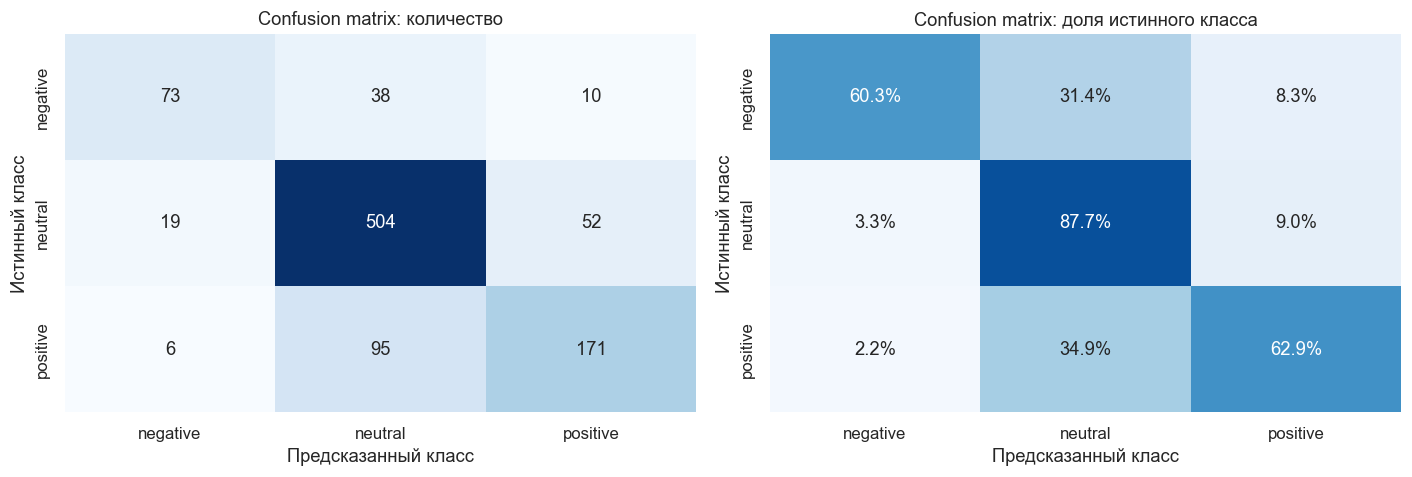

,Истинный класс,Всего,Верно,Ошибок,Recall,"Доля ошибок, %"
0,negative,121,73,48,0.6033,39.6694
1,neutral,575,504,71,0.8765,12.3478
2,positive,272,171,101,0.6287,37.1324


Какие классы модель путает:


,sentiment,predicted_sentiment,Количество
0,positive,neutral,95
1,neutral,positive,52
2,negative,neutral,38
3,neutral,negative,19
4,negative,positive,10
5,positive,negative,6


In [25]:
cm_best = confusion_matrix(analysis_df["label"], analysis_df["predicted_label"], labels=[0, 1, 2])
cm_best_normalized = cm_best / cm_best.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[0])
sns.heatmap(cm_best_normalized, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1,
            cbar=False, xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[1])
axes[0].set_title("Confusion matrix: количество")
axes[1].set_title("Confusion matrix: доля истинного класса")
for ax in axes:
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
fig.tight_layout()
plt.show()
plt.close(fig)

class_error_summary = pd.DataFrame({
    "Истинный класс": CLASS_ORDER,
    "Всего": cm_best.sum(axis=1),
    "Верно": cm_best.diagonal(),
    "Ошибок": cm_best.sum(axis=1) - cm_best.diagonal(),
    "Recall": cm_best.diagonal() / cm_best.sum(axis=1),
})
class_error_summary["Доля ошибок, %"] = 100 * class_error_summary["Ошибок"] / class_error_summary["Всего"]
display(class_error_summary.round(4))

error_directions = (errors_df.groupby(["sentiment", "predicted_sentiment"])
                    .size().rename("Количество").reset_index()
                    .sort_values("Количество", ascending=False, kind="stable").reset_index(drop=True))
print("Какие классы модель путает:")
display(error_directions)

### 3. Примеры ошибок разных классов

Для каждого истинного класса показываем до трёх реальных ошибок, отсортированных по
`source_row`. Это воспроизводимый выбор примеров, а не только самые удобные случаи.

In [26]:
with pd.option_context("display.max_colwidth", None):
    for sentiment in CLASS_ORDER:
        examples = errors_df.loc[errors_df["sentiment"].eq(sentiment)].sort_values("source_row").head(3)
        print(f"\nИстинный класс: {sentiment}; ошибок всего: {len(errors_df.loc[errors_df['sentiment'].eq(sentiment)])}")
        display(examples[["source_row", "text", "sentiment", "predicted_sentiment"]])

length_error_summary = (analysis_df.assign(Группа=analysis_df["is_error"].map({False: "Верно", True: "Ошибка"}))
                        .groupby("Группа")[["char_count", "word_count_clean"]]
                        .agg(["count", "mean", "median"]))
print("Длины верных и ошибочных текстов (описательная статистика):")
display(length_error_summary.round(2))


Истинный класс: negative; ошибок всего: 48


,source_row,text,sentiment,predicted_sentiment
413,415,A tinyurl link takes users to a scamming site promising that users can earn thousands of dollars by becoming a Google ( NASDAQ : GOOG ) Cash advertiser .,negative,neutral
498,500,One of the challenges in the oil production in the North Sea is scale formation that can plug pipelines and halt production .,negative,neutral
695,697,"Finnish power supply solutions and systems provider Efore Oyj said its net loss widened to 3.2 mln euro $ 4.2 mln for the first quarter of fiscal 2006-2007 ending October 31 , 2007 from 900,000 euro $ 1.2 mln for the same period of fiscal 2005-06 .",negative,positive



Истинный класс: neutral; ошибок всего: 71


,source_row,text,sentiment,predicted_sentiment
61,61,"When this investment is in place , Atria plans to expand into the Moscow market .",neutral,positive
71,71,"- So , the sales growth of cars considerably influence on the tires market '' .",neutral,positive
410,412,`` Management decided at the end of 2005 to increase cathode copper capacity .,neutral,positive



Истинный класс: positive; ошибок всего: 101


,source_row,text,sentiment,predicted_sentiment
19,19,"Its board of directors will propose a dividend of EUR0 .12 per share for 2010 , up from the EUR0 .08 per share paid in 2009 .",positive,neutral
25,25,"Net sales surged by 18.5 % to EUR167 .8 m. Teleste said that EUR20 .4 m , or 12.2 % , of the sales came from the acquisitions made in 2009 .",positive,neutral
125,127,"The circuit 's overall production rate on a weekly basis is now in excess of an average of 40,000 tonnes per day , with volumes in excess of 50,000 tonnes per day being reached on individual days .",positive,neutral


Длины верных и ошибочных текстов (описательная статистика):


char_count                word_count_clean              
            count    mean median            count   mean median
Группа                                                         
Верно         748  124.29  111.0              748  22.47   21.0
Ошибка        220  131.92  125.5              220  23.57   22.5

### 4. Разбор реальных ошибок и основные failure cases

Для выбранных примеров ниже записываем, что произошло и какие сложности видны в тексте.
Это ручная интерпретация примеров, а не доказательство того, какие именно признаки
вызвали решение модели. Все перечисленные `source_row` проверяем: они действительно
должны быть ошибками текущей лучшей модели.

In [27]:
manual_error_notes = [
    {
        "source_row": 697,
        "Случай": "Увеличение убытка",
        "Разбор": "Убыток вырос с 0.9 до 3.2 млн евро: negative, но модель предсказала positive. Нужно учитывать, какой показатель растёт: рост убытка означает ухудшение.",
    },
    {
        "source_row": 19,
        "Случай": "Сравнение чисел и рост дивидендов",
        "Разбор": "Предлагаемый дивиденд вырос с EUR0.08 до EUR0.12: positive, но модель выбрала neutral. TF-IDF не вычисляет изменение числовых показателей напрямую.",
    },
    {
        "source_row": 25,
        "Случай": "Рост продаж в длинной новости",
        "Разбор": "Продажи выросли на 18.5%, затем перечислены суммы и вклад приобретений: positive распознан как neutral. Возможная сложность — выделение главного результата среди дополнительных деталей.",
    },
    {
        "source_row": 61,
        "Случай": "Планы вместо достигнутого результата",
        "Разбор": "Компания планирует расширение на московский рынок. Метка neutral, предсказание positive: план расширения не равен уже полученной прибыли.",
    },
    {
        "source_row": 71,
        "Случай": "Позитивное слово в нейтральном утверждении",
        "Разбор": "Общее утверждение о влиянии роста продаж автомобилей на рынок шин имеет метку neutral, но предсказано positive. Слово growth само по себе не определяет тональность всего предложения.",
    },
    {
        "source_row": 415,
        "Случай": "Мошенничество и обещание заработка",
        "Разбор": "Текст описывает мошеннический сайт, обещающий заработок: negative распознан как neutral. Обещание дохода здесь относится к мошенничеству; важен контекст, а не только денежная лексика.",
    },
    {
        "source_row": 500,
        "Случай": "Отраслевой риск остановки производства",
        "Разбор": "Отложения могут закупорить трубопроводы и остановить производство: negative распознан как neutral. Негативный смысл выражен техническими последствиями для бизнеса.",
    },
]
manual_error_review = pd.DataFrame(manual_error_notes)
assert set(manual_error_review["source_row"]).issubset(set(errors_df["source_row"]))
manual_error_review = manual_error_review.merge(
    errors_df[["source_row", "text", "sentiment", "predicted_sentiment"]],
    on="source_row", how="left", validate="one_to_one",
)
with pd.option_context("display.max_colwidth", None):
    for row in manual_error_review.to_dict("records"):
        print(f"\nСтрока {row['source_row']}: {row['sentiment']} → {row['predicted_sentiment']}")
        print("Текст:", row["text"])
        print("Разбор:", row["Разбор"])


Строка 697: negative → positive
Текст: Finnish power supply solutions and systems provider Efore Oyj said its net loss widened to 3.2 mln euro $ 4.2 mln for the first quarter of fiscal 2006-2007 ending October 31 , 2007 from 900,000 euro $ 1.2 mln for the same period of fiscal 2005-06 .
Разбор: Убыток вырос с 0.9 до 3.2 млн евро: negative, но модель предсказала positive. Нужно учитывать, какой показатель растёт: рост убытка означает ухудшение.

Строка 19: positive → neutral
Текст: Its board of directors will propose a dividend of EUR0 .12 per share for 2010 , up from the EUR0 .08 per share paid in 2009 .
Разбор: Предлагаемый дивиденд вырос с EUR0.08 до EUR0.12: positive, но модель выбрала neutral. TF-IDF не вычисляет изменение числовых показателей напрямую.

Строка 25: positive → neutral
Текст: Net sales surged by 18.5 % to EUR167 .8 m. Teleste said that EUR20 .4 m , or 12.2 % , of the sales came from the acquisitions made in 2009 .
Разбор: Продажи выросли на 18.5%, затем перечислены 

### 5. Выводы и что улучшать дальше

**Основные наблюдения из примеров:**

- Рост показателя требует понимания его смысла: рост прибыли и рост убытка имеют разную тональность.
- Важны сравнения чисел и финансовый контекст, а не отдельные слова или суммы.
- Планы и общие рыночные утверждения могут ошибочно восприниматься как достигнутый позитивный результат.
- Технические риски и мошенничество могут выражать негатив без привычных слов о падении прибыли.

**Возможные следующие эксперименты:**

1. Собрать больше размеченных примеров негативных последствий и количественных изменений;
   отдельно проверить «рост прибыли / рост убытка» и «план / результат».
2. Проверить финансовые контекстные представления текста и признаки изменения показателей:
   они могут помочь учитывать, что именно выросло и с чем сравнивается значение.
3. Проверить веса классов на кросс-валидации внутри train: сейчас recall для negative
   и positive заметно ниже, чем для neutral.

Это предложения для будущих экспериментов, а не уже проверенные улучшения.
Примеры test не переносим в train. Так как test уже использован для выбора модели и анализа,
для независимой оценки последующих изменений понадобится новая отложенная выборка.

In [28]:
most_common_error = error_directions.iloc[0] if len(error_directions) else None
weakest_class = class_error_summary.loc[class_error_summary["Recall"].idxmin()]
correct_mean_length = analysis_df.loc[~analysis_df["is_error"], "char_count"].mean()
error_mean_length = errors_df["char_count"].mean()

error_analysis_text = f"""
**Результат Дня 5**

- Модель: **{best_method}**.
- Ошибок: **{error_count} из {len(analysis_df)}** ({error_count / len(analysis_df):.2%});
  верных ответов — **{correct_count}**.
- Чаще всего путаются **{most_common_error['sentiment']} → {most_common_error['predicted_sentiment']}**:
  **{int(most_common_error['Количество'])}** случаев.
- Самый низкий recall у **{weakest_class['Истинный класс']}**:
  **{weakest_class['Recall']:.2%}**. Это доля найденных примеров данного класса.
- Средняя длина ошибочного текста — **{error_mean_length:.1f}** символа,
  верного — **{correct_mean_length:.1f}**. Это описательное различие, которое само по себе
  не доказывает влияние длины на ошибки.
- Построены confusion matrix в количествах и долях, таблица направлений ошибок,
  показаны примеры каждого истинного класса и вручную разобраны **{len(manual_error_review)}** ошибок.

**Все критерии classification_day05.txt выполнены:** есть error analysis, confusion matrix,
разбор реальных ошибок, основные failure cases и предложения дальнейших улучшений.

Все результаты находятся в этом ноутбуке: `analysis_df`, `errors_df`, `cm_best`,
`class_error_summary`, `error_directions`, `manual_error_review` и их сохранённые выводы.

**Следующий этап по classification_day06.txt:** сохранение и загрузка лучшей модели
и векторизатора, функция предсказания с той же очисткой, новые примеры и описание формата входа/выхода.
"""
display(Markdown(error_analysis_text))

assert int(cm_best.sum()) == len(analysis_df)
assert int(cm_best.trace()) == correct_count
assert int(error_directions["Количество"].sum()) == error_count
assert int(class_error_summary["Ошибок"].sum()) == error_count
assert abs(correct_count / len(analysis_df) - best_accuracy) < 1e-12
assert set(errors_df["source_row"]).isdisjoint(set(train_df["source_row"]))
print("Проверки анализа ошибок пройдены.")


**Результат Дня 5**

- Модель: **Другая модель: TF-IDF (1, 2) + LinearSVC**.
- Ошибок: **220 из 968** (22.73%);
  верных ответов — **748**.
- Чаще всего путаются **positive → neutral**:
  **95** случаев.
- Самый низкий recall у **negative**:
  **60.33%**. Это доля найденных примеров данного класса.
- Средняя длина ошибочного текста — **131.9** символа,
  верного — **124.3**. Это описательное различие, которое само по себе
  не доказывает влияние длины на ошибки.
- Построены confusion matrix в количествах и долях, таблица направлений ошибок,
  показаны примеры каждого истинного класса и вручную разобраны **7** ошибок.

**Все критерии classification_day05.txt выполнены:** есть error analysis, confusion matrix,
разбор реальных ошибок, основные failure cases и предложения дальнейших улучшений.

Все результаты находятся в этом ноутбуке: `analysis_df`, `errors_df`, `cm_best`,
`class_error_summary`, `error_directions`, `manual_error_review` и их сохранённые выводы.

**Следующий этап по classification_day06.txt:** сохранение и загрузка лучшей модели
и векторизатора, функция предсказания с той же очисткой, новые примеры и описание формата входа/выхода.


Проверки анализа ошибок пройдены.


## День 6 из 7. Inference pipeline и сохранение модели

**Источник требований:** `classification_day06.txt` из присланной папки задания.
Цель — сохранить лучшую модель и делать предсказания на новых текстах без переобучения.
Берём победителя Дня 4: уже обученные `best_model` и `best_vectorizer`.

Код остаётся в этом ноутбуке. Сохранённые модель и векторизатор — два выходных файла
в папке `models` рядом с ноутбуком; это не дополнительные файлы с кодом.
Для запуска используйте рабочую папку ядра, в которой находится `financial_sentiment.ipynb`.

### 1. Сохранение лучшей модели и векторизатора

Эту ячейку выполняем после Дней 1–4. Она сохраняет именно выбранные обученные объекты,
а не обучает их заново. При повторном запуске файлы обновляются.

In [29]:
from pathlib import Path
import joblib

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "best_model.pkl"
vectorizer_path = MODEL_DIR / "vectorizer.pkl"

joblib.dump(best_model, model_path)
joblib.dump(best_vectorizer, vectorizer_path)
assert model_path.is_file() and vectorizer_path.is_file()
print("Сохранена модель:", best_method)
print("Модель:", model_path.as_posix())
print("Векторизатор:", vectorizer_path.as_posix())

Сохранена модель: Другая модель: TF-IDF (1, 2) + LinearSVC
Модель: models/best_model.pkl
Векторизатор: models/vectorizer.pkl


### 2. Загрузка без переобучения

Для следующих предсказаний загружаем файлы с диска. Эти ячейки не используют `fit`.
`loaded_model` и `loaded_vectorizer` — отдельные загруженные объекты.

**После перезапуска ядра:** выполните импорты из Дня 1, ячейку с определением `clean_text`
из Дня 2, затем разделы 2–4 Дня 6. Датасет скачивать и Дни 3–5 повторять не нужно.
Файлы `models/best_model.pkl` и `models/vectorizer.pkl` должны уже существовать.

In [30]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

MODEL_DIR = Path("models")
loaded_model = joblib.load(MODEL_DIR / "best_model.pkl")
loaded_vectorizer = joblib.load(MODEL_DIR / "vectorizer.pkl")
INFERENCE_LABELS = {0: "negative", 1: "neutral", 2: "positive"}
print("Загружена модель:", type(loaded_model).__name__)
print("Загружен векторизатор:", type(loaded_vectorizer).__name__)
print("Размер словаря:", len(loaded_vectorizer.vocabulary_))

Загружена модель: LinearSVC
Загружен векторизатор: TfidfVectorizer
Размер словаря: 5000


### 3. Функция предсказания: вход, очистка и выход

**Вход:** одна непустая строка либо непустой список строк на английском языке.
Числа, `None`, пустой список и тексты, пустые после очистки, отклоняются с понятной ошибкой.

Функция применяет ту же `clean_text` из Дня 2, затем вызывает только `transform` и `predict`.
**Выход:** таблица, одна строка на входной текст: `text`, `text_clean`, `label` (0/1/2),
`sentiment` (negative/neutral/positive).

У выбранного LinearSVC нет `predict_proba`, поэтому вероятности не выводим.
Значения его `decision_function` не являются вероятностями.

In [31]:
def predict_sentiment(texts, model, vectorizer, clean_func=clean_text):
    """Предсказать тональность одной строки или списка строк без обучения."""
    if isinstance(texts, str):
        texts = [texts]
    elif not isinstance(texts, list):
        raise TypeError("Передайте строку или список строк")
    if not texts:
        raise ValueError("Список текстов не должен быть пустым")
    if not all(isinstance(text, str) for text in texts):
        raise TypeError("Каждый текст должен быть строкой")

    cleaned = [clean_func(text) for text in texts]
    empty_positions = [i for i, text in enumerate(cleaned) if not text]
    if empty_positions:
        raise ValueError(f"Пустые тексты после очистки, позиции с нуля: {empty_positions}")

    features = vectorizer.transform(cleaned)
    labels = model.predict(features)
    return pd.DataFrame({
        "text": texts,
        "text_clean": cleaned,
        "label": labels,
        "sentiment": [INFERENCE_LABELS[int(label)] for label in labels],
    })

### 4. Предсказания на новых примерах

Это пять новых учебных формулировок, а не дополнительная размеченная тестовая выборка.
Результаты демонстрируют работу функции, но не заменяют метрики качества Дня 4.
Первый текст специально содержит HTML и лишние пробелы для проверки той же очистки.

In [32]:
demo_texts = [
    " <b>Operating profit</b> increased by 25% as demand improved. ",
    "The company reported a sharp decline in revenue and a net loss.",
    "The company will publish its annual report next Tuesday.",
    "The board proposed a higher dividend after record earnings.",
    "The factory will close, resulting in 500 job losses.",
]
demo_predictions = predict_sentiment(demo_texts, loaded_model, loaded_vectorizer)
with pd.option_context("display.max_colwidth", None):
    display(demo_predictions)

single_prediction = predict_sentiment(demo_texts[0], loaded_model, loaded_vectorizer)
print("Одна строка → одна строка результата:")
display(single_prediction[["label", "sentiment"]])

,text,text_clean,label,sentiment
0,<b>Operating profit</b> increased by 25% as demand improved.,operating profit increased by 25% as demand improved.,2,positive
1,The company reported a sharp decline in revenue and a net loss.,the company reported a sharp decline in revenue and a net loss.,0,negative
2,The company will publish its annual report next Tuesday.,the company will publish its annual report next tuesday.,1,neutral
3,The board proposed a higher dividend after record earnings.,the board proposed a higher dividend after record earnings.,1,neutral
4,"The factory will close, resulting in 500 job losses.","the factory will close, resulting in 500 job losses.",0,negative


Одна строка → одна строка результата:


,label,sentiment
0,2,positive


### 5. Проверка сохранения, загрузки и единой обработки

Проверяем совпадение результатов до и после сохранения на всём test, а также
предсказания для одного текста и списка. В этом разделе используются переменные Дней 3–4;
для обычного inference после перезапуска ядра этот раздел выполнять не требуется.

In [33]:
# Загруженная пара даёт те же предсказания, что и лучший Pipeline до сохранения.
loaded_test_predictions = loaded_model.predict(loaded_vectorizer.transform(X_test))
np.testing.assert_array_equal(loaded_test_predictions, y_pred_best)
assert loaded_vectorizer.vocabulary_ == best_vectorizer.vocabulary_
np.testing.assert_allclose(loaded_vectorizer.idf_, best_vectorizer.idf_)

# Одна строка и список из неё должны обрабатываться одинаково.
pd.testing.assert_frame_equal(single_prediction, demo_predictions.iloc[[0]].reset_index(drop=True))
assert demo_predictions["text_clean"].tolist() == [clean_text(text) for text in demo_texts]
assert demo_predictions["text_clean"].iloc[0] == "operating profit increased by 25% as demand improved."
np.testing.assert_array_equal(
    demo_predictions["label"].to_numpy(),
    best_pipeline.predict([clean_text(text) for text in demo_texts]),
)
assert len(demo_predictions) == 5
assert demo_predictions["sentiment"].isin(INFERENCE_LABELS.values()).all()
assert not set(demo_predictions["text_clean"]) & set(df_prepared["text_clean"])

# Некорректный ввод отклоняется до обращения к модели.
for bad_input in [[], "   ", "<b> </b>", None, ["Valid text", None]]:
    try:
        predict_sentiment(bad_input, loaded_model, loaded_vectorizer)
    except (TypeError, ValueError):
        pass
    else:
        raise AssertionError(f"Ожидалась ошибка для {bad_input!r}")

print("Проверки пройдены: сохранение/загрузка, совпадение test-предсказаний,")
print("общая очистка, один текст/список и обработка некорректного ввода.")

Проверки пройдены: сохранение/загрузка, совпадение test-предсказаний,
общая очистка, один текст/список и обработка некорректного ввода.


### 6. Итоги Дня 6

- Лучшая модель и TF-IDF сохранены в `models/best_model.pkl` и `models/vectorizer.pkl`.
- Объекты загружаются с диска, их предсказания совпадают с исходной моделью на всём test.
- Реализована `predict_sentiment` для одной строки и списка строк.
- На inference применяется та же очистка, что на обучении.
- Показаны пять новых примеров; описаны формат входа и выхода и запуск без переобучения.

**Все критерии classification_day06.txt выполнены.** Код и результаты остаются в одном ноутбуке,
а два файла в `models` содержат обученную модель и векторизатор.

**Следующий этап по classification_day07.txt:** финальная структура, README с инструкциями,
демонстрация, сводка метрик и ошибок, ограничения и проверка запуска.

## День 7 из 7. Финализация classification mini-product

**Источник требований:** `classification_day07.txt` из присланной папки задания.
Сегодня собираем инструкцию, демонстрацию, сводку метрик и ошибок, ограничения и проверку запуска.

### 1. README — задача и структура проекта

**Финансовые новости — анализ тональности.** Учебная система получает английский текст
финансовой новости и предсказывает `negative` (0), `neutral` (1) или `positive` (2).

Код, README, графики, таблицы и выводы находятся в одном Jupyter-ноутбуке.
Отдельные Python-скрипты и отдельный README не нужны.

```text
nlp/
├── financial_sentiment.ipynb   # Дни 1–7, код, README и результаты
└── models/
    ├── best_model.pkl         # Обученный LinearSVC
    └── vectorizer.pkl         # Обученный TF-IDF
```

Папка `models` создаётся в День 6. При передаче проекта для предсказаний без обучения
передайте всю эту папку вместе с ноутбуком. Для обучения с нуля достаточно ноутбука:
данные скачиваются автоматически, а два файла модели создаются заново.

**Разделы:** День 1 — данные и EDA; День 2 — очистка; День 3 — baseline;
День 4 — три улучшения; День 5 — error analysis; День 6 — сохранение и inference;
День 7 — инструкция и финальная проверка.

### 2. README — датасет и окружение

Датасет: [Financial PhraseBank](https://huggingface.co/datasets/takala/financial_phrasebank),
`Sentences_50Agree.txt` — английские предложения из финансовых новостей с согласием
аннотаторов от 50%. Версия источника и SHA-256 проверяются в Дне 1.
В исходном файле 4 846 строк, после подготовки — 4 836. Удалены 6 дубликатов
и 4 строки с конфликтующими метками. Лицензия: CC BY-NC-SA 3.0; авторы и ссылка на статью — в Дне 1.

Проверенное окружение: **Python 3.13.5**, pandas 2.2.3, NumPy 2.1.3,
matplotlib 3.10.0, seaborn 0.13.2, scikit-learn 1.6.1, joblib 1.4.2,
ipykernel 6.29.5, IPython 8.30.0.
Для сохранённых `.pkl` используйте те же версии scikit-learn и joblib.

Если пакеты ещё не установлены, выполните в отдельной ячейке и перезапустите ядро:

```python
%pip install pandas==2.2.3 numpy==2.1.3 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 joblib==1.4.2 ipykernel==6.29.5 ipython==8.30.0
```

### 3. README — как запустить обучение

1. Откройте папку `nlp` в VS Code или Jupyter и выберите Python-ядро
   с установленными пакетами. Рабочая папка ядра должна содержать `financial_sentiment.ipynb`.
2. Для первого запуска нужен интернет: День 1 скачивает небольшой архив датасета.
3. Выполните **Restart Kernel and Run All / Перезапустить ядро и выполнить всё**.
4. Дни 1–2 загрузят и подготовят данные; День 3 обучит baseline; День 4 проверит
   три улучшения; День 5 разберёт ошибки; День 6 сохранит лучшую модель и векторизатор.
5. В конце появятся результаты Дня 7 и сообщение об успешной проверке.
   Сохраните ноутбук, чтобы таблицы и графики остались внутри файла.

Разбиение фиксировано: train — 3 868 строк, test — 968, `random_state=42`, со стратификацией.
TF-IDF обучается только на train. Подбор `C` выполняется по macro F1 с тремя CV-фолдами
внутри train, причём TF-IDF обучается заново внутри каждого фолда.

### 4. README — как запустить inference без обучения

Если два файла в `models` уже есть, после перезапуска ядра выполните только:

1. День 1: ячейку импортов, начинающуюся с `import hashlib` — без загрузки данных.
2. День 2: ячейку с `import html` и определением `clean_text`.
3. День 6: ячейку раздела 2 с `joblib.load`.
4. День 6: определение `predict_sentiment` из раздела 3.
5. Передайте свой текст или выполните demo-ячейку раздела 4.

Дни 3–5 и ячейку сохранения модели повторять не нужно. Для inference интернет не нужен.

```python
predict_sentiment(
    "Operating profit increased by 25%.",
    loaded_model,
    loaded_vectorizer,
)
```

Вход — непустая английская строка либо непустой список строк.
Выход — таблица с `text`, `text_clean`, `label`, `sentiment`.
Очистка совпадает с обучением. У LinearSVC нет `predict_proba`, поэтому вероятности не выводятся.
Пустые тексты и некорректные типы отклоняются с сообщением об ошибке.

### 5. README — метрики и краткие результаты

Baseline — TF-IDF `(1, 2)` + Logistic Regression.
Проверены три улучшения: триграммы, LinearSVC и подбор `C` Logistic Regression.
Все варианты оценены на одних test-строках. Ниже сводка рассчитанных результатов, а не новые эксперименты.

In [34]:
final_results = experiment_results[["Метод", "Macro F1", "Accuracy", "Улучшение, %"]].copy()
display(final_results.round(4))
final_summary = f"""
Лучший вариант — **{best_method}**: test macro F1 **{best_f1:.4f}**,
accuracy **{best_accuracy:.4f}**. Baseline macro F1 — **{baseline_f1:.4f}**.
Относительное улучшение — **{relative_improvement:+.2f}%**.
Цель общего README +5% **{'достигнута' if relative_improvement >= 5 else 'пока не достигнута'}**.

**Error analysis:** **{error_count}** ошибок из **{len(analysis_df)}**.
Чаще всего модель путает **{most_common_error['sentiment']} → {most_common_error['predicted_sentiment']}**
(**{int(most_common_error['Количество'])}** случаев).
В Дне 5 есть confusion matrix, ошибки каждого класса и ручной разбор **{len(manual_error_review)}** примеров.
Основные сложности — смысл роста числовых показателей, планы вместо результата,
нейтральные утверждения с позитивной лексикой и отраслевые риски.
"""
display(Markdown(final_summary))

,Метод,Macro F1,Accuracy,"Улучшение, %"
0,"Baseline: TF-IDF (1, 2) + LogReg",0.6918,0.7717,0.0000
1,"Триграммы: TF-IDF (1, 3) + LogReg",0.6948,0.7738,0.4295
2,"Другая модель: TF-IDF (1, 2) + LinearSVC",0.7252,0.7727,4.8253
3,"Подбор C: TF-IDF (1, 2) + LogReg",0.7146,0.7665,3.2965



Лучший вариант — **Другая модель: TF-IDF (1, 2) + LinearSVC**: test macro F1 **0.7252**,
accuracy **0.7727**. Baseline macro F1 — **0.6918**.
Относительное улучшение — **+4.83%**.
Цель общего README +5% **пока не достигнута**.

**Error analysis:** **220** ошибок из **968**.
Чаще всего модель путает **positive → neutral**
(**95** случаев).
В Дне 5 есть confusion matrix, ошибки каждого класса и ручной разбор **7** примеров.
Основные сложности — смысл роста числовых показателей, планы вместо результата,
нейтральные утверждения с позитивной лексикой и отраслевые риски.


### 6. Демонстрация

Используем пять новых формулировок Дня 6 и уже загруженные объекты.
Для наглядности добавляем ожидаемую человеком тональность. Эти ожидания не являются
экспертной разметкой или отдельным тестовым датасетом; демонстрация может содержать ошибку.

In [35]:
final_demo = predict_sentiment(demo_texts, loaded_model, loaded_vectorizer)
final_demo["Ожидаемая тональность"] = ["positive", "negative", "neutral", "positive", "negative"]
final_demo["Совпало с ожиданием"] = final_demo["sentiment"].eq(final_demo["Ожидаемая тональность"])
with pd.option_context("display.max_colwidth", None):
    display(final_demo[["text", "Ожидаемая тональность", "sentiment", "Совпало с ожиданием"]])
print("Совпадений с учебными ожиданиями:", int(final_demo["Совпало с ожиданием"].sum()), "из", len(final_demo))
print("Это демонстрация, а не оценка accuracy на независимом датасете.")

,text,Ожидаемая тональность,sentiment,Совпало с ожиданием
0,<b>Operating profit</b> increased by 25% as demand improved.,positive,positive,True
1,The company reported a sharp decline in revenue and a net loss.,negative,negative,True
2,The company will publish its annual report next Tuesday.,neutral,neutral,True
3,The board proposed a higher dividend after record earnings.,positive,neutral,False
4,"The factory will close, resulting in 500 job losses.",negative,negative,True


Совпадений с учебными ожиданиями: 4 из 5
Это демонстрация, а не оценка accuracy на независимом датасете.


### 7. Ограничения модели

- Модель рассчитана на английские финансовые предложения; качество для русского языка,
  длинных статей, соцсетей и других тематик не проверялось.
- У аннотаторов выбранной подвыборки согласие от 50%; некоторые метки могут быть спорными.
- TF-IDF со словами и парами слов ограниченно учитывает контекст, отрицания и связи между
  числами. Например, рост убытка и рост прибыли требуют разной интерпретации.
- Классы несбалансированы. Negative и positive распознаются хуже, чем neutral;
  подробные показатели и примеры есть в Дне 5.
- Лучший вариант выбран по этому же test, а его ошибки уже просмотрены.
  Это учебная сравнительная оценка; независимая проверка после выбора модели не проводилась.
- Ни одно улучшение пока не достигло цели общего README +5%: лучший прирост составляет 4.83%.
- В demo фраза о повышении дивидендов после рекордной прибыли предсказана как neutral,
  хотя ожидается positive. Этот пример оставлен, чтобы показать реальное ограничение модели.
- Тональность новости не является прогнозом движения цены или готовым торговым сигналом:
  модель не использует котировки, время публикации и реакцию рынка.

### 8. Финальная проверка полного workflow

Проверяем наличие данных и артефактов, непересекающееся разбиение, метрики,
согласованность error analysis и совпадение предсказаний после загрузки модели.

In [36]:
final_checks = {
    "Данные подготовлены, три класса": len(df_prepared) == 4836 and set(df_prepared["label"]) == {0, 1, 2},
    "Разбиение train/test без пересечений": (
        len(train_df) + len(test_df) == len(df_prepared)
        and set(train_df["text_clean"]).isdisjoint(test_df["text_clean"])
    ),
    "Baseline и три эксперимента зафиксированы": len(experiment_results) == 4,
    "Macro F1 соответствует предсказаниям": abs(f1_score(y_test, y_pred_best, average="macro") - best_f1) < 1e-12,
    "Confusion matrix и число ошибок согласованы": int(cm_best.sum() - cm_best.trace()) == len(errors_df),
    "Реальные ошибки разобраны": len(manual_error_review) == 7,
    "Модель и TF-IDF сохранены": (MODEL_DIR / "best_model.pkl").is_file() and (MODEL_DIR / "vectorizer.pkl").is_file(),
    "Предсказания после загрузки совпадают": np.array_equal(loaded_test_predictions, y_pred_best),
    "Demo использует загруженную модель": len(final_demo) == 5 and final_demo["sentiment"].isin(INFERENCE_LABELS.values()).all(),
}
final_check_table = pd.DataFrame({
    "Проверка": list(final_checks),
    "Результат": ["Пройдено" if passed else "Ошибка" for passed in final_checks.values()],
})
display(final_check_table)
assert all(final_checks.values()), "Не все финальные проверки пройдены"
print("Все финальные проверки пройдены. Дни 1–7 выполнены.")

,Проверка,Результат
0,"Данные подготовлены, три класса",Пройдено
1,Разбиение train/test без пересечений,Пройдено
2,Baseline и три эксперимента зафиксированы,Пройдено
3,Macro F1 соответствует предсказаниям,Пройдено
4,Confusion matrix и число ошибок согласованы,Пройдено
5,Реальные ошибки разобраны,Пройдено
6,Модель и TF-IDF сохранены,Пройдено
7,Предсказания после загрузки совпадают,Пройдено
8,Demo использует загруженную модель,Пройдено


Все финальные проверки пройдены. Дни 1–7 выполнены.


### 9. Соответствие classification_day07.txt

| Требование | Где выполнено |
|---|---|
| Понятная структура | README: раздел 1, один ноутбук и два артефакта модели |
| README: задача, датасет, обучение, inference, метрики | Разделы 1–5 Дня 7 |
| Demo-примеры | День 6 и раздел 6 Дня 7 |
| Baseline, лучший вариант, error analysis | Раздел 5 Дня 7, подробности в Днях 3–5 |
| Проверка запуска по инструкции | Полный Run All и отдельный inference после загрузки файлов |
| Явные ограничения | Раздел 7 Дня 7 |

Проект проходит цикл **данные → подготовка → baseline → улучшения → анализ ошибок → сохранение → предсказания**.

**Проверка запуска выполнена:** полный Run All прошёл в отдельной копии проекта, где
сначала был только ноутбук, в установленном окружении. Inference отдельно прошёл в новом
Python-процессе с заблокированными обращениями к сети и методами обучения; использованы
только документированные ячейки импортов, очистки, загрузки, функции и demo.
